# <center>Fisher forecast for HM</center>
### <center>By Junsong Cang</center>


Set up required packages

In [1]:
plot_path = '/Users/cangtao/Desktop/'

import numpy as np
import sys, platform, tqdm, h5py
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import PyLab as PL
from getdist import plots
if platform.system() == 'Darwin':
    sys.path.insert(1, '/Users/cangtao/FileVault/GitHub/ResearchArchive/Hongmeng_SDM_2025_AA_SSPMA/ToolKit/')
else:
    sys.path.insert(1, '/afs/ihep.ac.cn/users/z/zhangzixuan/work/cjs/SDM_lite/ToolKit/')
import Fisher_ToolKit as FST
plt.rcParams.update({
    'text.usetex': True,
    'font.family':'Times',
    'text.latex.preamble': r'\usepackage{newtxtext,newtxmath}'})
%matplotlib inline
%load_ext autoreload
%autoreload 2
%matplotlib widget

# Compute and plot limits

Compute Limits

In [2]:
block_sun = 1
mx_ax = np.linspace(-4, 3, 15)
NFG = 7
dx_ax = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01])

nm = len(mx_ax)
Tobs = [1/12, 1, 5]
nt = len(Tobs)
sx = np.zeros([nt, nm])
sx_II = np.zeros([nt, nm])

for mid in tqdm.tqdm(range(nm), desc = 'Computing SDM Limits'):
    for tid in [0, 1, 2]:
        T = Tobs[tid]
        # main results
        sx[tid, mid] = 1E-42*FST.Compute_Fisher_Matrix(
            mx = mx_ax[mid],
            dx_ax = dx_ax,
            Tobs = T,
            NFG = NFG,
            block_sun = block_sun,
            params_to_exclude = ['ALW', 'E0', 'aesc'])['sx42_limit']
        # Pop II only
        sx_II[tid, mid] = 1E-42*FST.Compute_Fisher_Matrix(
            mx = mx_ax[mid],
            dx_ax = dx_ax,
            Tobs = T,
            NFG = NFG,
            block_sun = block_sun,
            params_to_exclude = ['ALW', 'E0', 'aesc', 'fst3', 'fesc3', 'LX3', 'ast3'])['sx42_limit']

Computing SDM Limits: 100%|██████████| 15/15 [00:10<00:00,  1.42it/s]


Plot Limits

Improvement after 0.08 years of observation: 4.15
Improvement after 1.00 years of observation: 16.84
Improvement after 5.00 years of observation: 38.88
Improvement after fixing PopIII 0.73
Maximum improvement after fixing PopIII 2.46


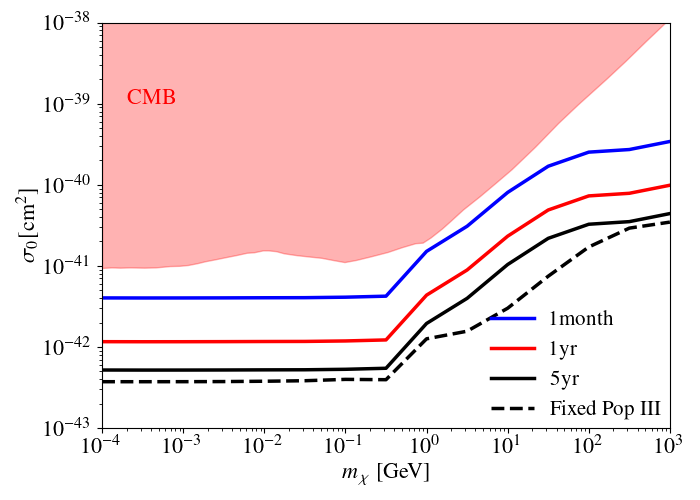

In [3]:
LineWidth = 2.5
FontSize = 16

mx = 10.0**mx_ax
data_CMB = np.load('/Users/cangtao/FileVault/GitHub/ResearchArchive/Hongmeng_SDM_2025_AA_SSPMA/data/2505.03148.Fig.6.CMB.npz')
m_CMB = 10**data_CMB['x']
s_CMB = 10**data_CMB['y']

fig, ax = plt.subplots()
#ax.grid(True, which='major', linewidth = 0.3) # v3: A&A Journal does not allow background grid
fig.set_size_inches(7, 5)

plt.plot(mx, sx[0,:], 'b', linewidth=LineWidth, label = '1month')
plt.plot(mx, sx[1,:], 'r', linewidth=LineWidth, label = '1yr')
plt.plot(mx, sx[2,:], 'k', linewidth=LineWidth, label = '5yr')
plt.plot(mx, sx_II[2,:], '--k', linewidth=LineWidth, label = 'Fixed Pop III')

plt.fill_between(m_CMB, s_CMB, 1E-30, color = 'r',alpha=0.3)#,label='CMB')

plt.xlabel('$m_\chi$ [GeV]',fontsize=FontSize,fontname='Times New Roman')
plt.ylabel('$\sigma_0[{\\rm cm^2}]$',fontsize=FontSize,fontname='Times New Roman')
plt.xticks(size=FontSize)
plt.yticks(size=FontSize)
plt.xscale('log')
plt.yscale('log')
plt.text(2E-4, 1E-39, 'CMB', size=FontSize, rotation = 0, color='r')

plt.xlim([1E-4, 1E3])
plt.ylim([1E-43, 1E-38])
plt.legend(fontsize=FontSize/1.05,loc = 'lower right', framealpha = 0, bbox_to_anchor=(1.00, 0.00), borderaxespad=0.0)
plt.tight_layout()
plt.savefig(plot_path + "Forecast_Limits.pdf", bbox_inches = 'tight')

# HM VS CMB: print results to quote in paper, fix to mx
m_CMB[0] = 0.99E-4
m_CMB[-1] = 1.001E3
sx_CMB = np.interp(x=mx, xp=m_CMB, fp=s_CMB, left=np.nan, right=np.nan)
for idx in [0, 1, 2]:
    sx_HM = np.interp(x=mx, xp=mx, fp=sx[idx,:], left=np.nan, right=np.nan)
    dif = np.mean(np.abs(1-sx_CMB/sx_HM))
    print("Improvement after {:.2f} years of observation: {:.2f}".format(Tobs[idx],dif))

# Vary VS Fix PopIII: print results to quote in paper
dif = np.mean(np.abs(1-sx[2,:]/sx_II[2,:]))
print("Improvement after fixing PopIII {:.2f}".format(dif))

dif = np.max(np.abs(1-sx[2,:]/sx_II[2,:]))
print("Maximum improvement after fixing PopIII {:.2f}".format(dif))


# GetDist

Generate Samples

In [4]:
mx = -4
params_exclude = ['E0', 'ALW', 'aesc']
NFG = 7
n_samples = 100000

if NFG == 5:
    dx_ax = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01])
else:
    dx_ax = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.10, 0.01])
        
data_1 = FST.Compute_Fisher_Matrix(
    params_to_exclude = ['ALW', 'E0', 'aesc'],
    mx = mx,
    get_samples = 1,
    Tobs = 5,
    dx_ax = dx_ax,
    n_samples = n_samples,
    NFG = NFG)

data_2 = FST.Compute_Fisher_Matrix(
    params_to_exclude = ['ALW', 'E0', 'aesc', 'fst3', 'fesc3', 'LX3', 'ast3'],
    mx = mx,
    get_samples = 1,
    Tobs = 5,
    dx_ax = dx_ax,
    n_samples = n_samples,
    NFG = NFG)



Removed no burn in
Removed no burn in


Plot Samples

Level of enhancement in astro constraints
fst : 9.028
fesc : 1.567
LX : 5.271
ast : 7.066


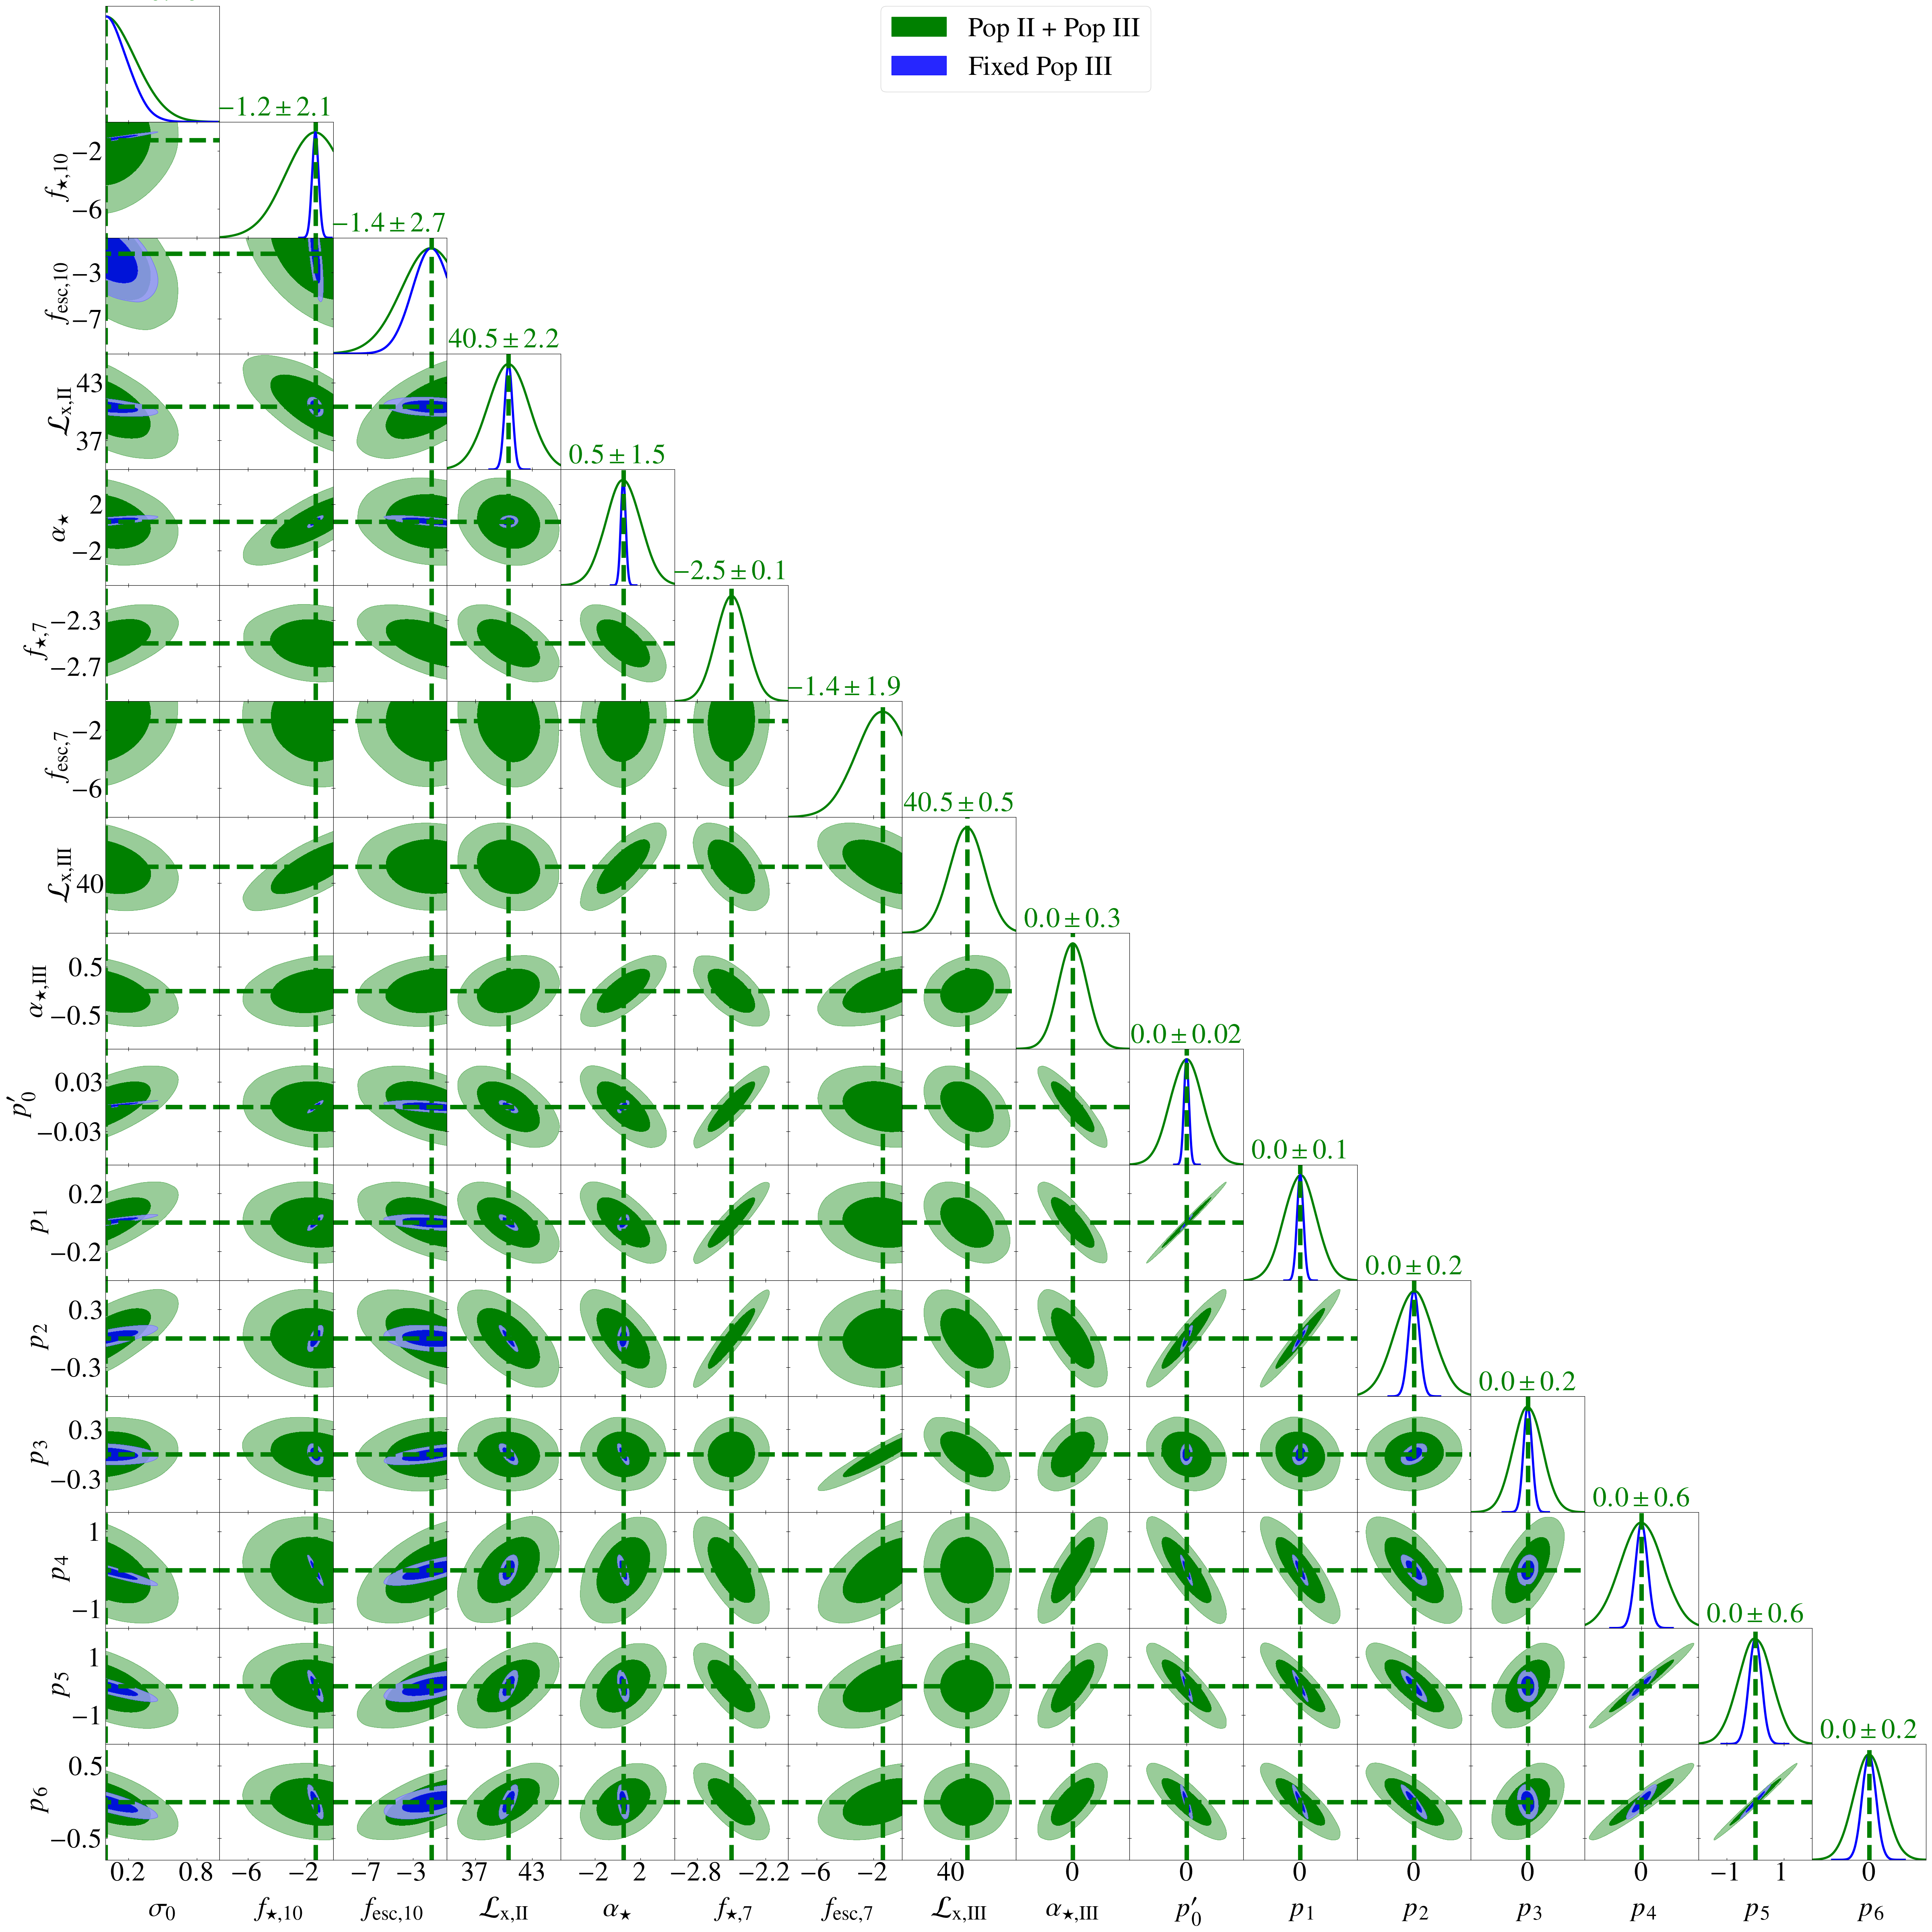

In [5]:
fontsize = 50
LineWidth = 8

ParamNames = data_1['names']
PlotNames = ['sx42', 'fst', 'fesc', 'LX', 'ast', 'fst3', 'fesc3', 'LX3', 'ast3', 'FG0', 'FG1', 'FG2', 'FG3', 'FG4', 'FG5', 'FG6']

print("Level of enhancement in astro constraints")
for name in ['fst', 'fesc', 'LX', 'ast']:
    sigma_1 = data_1['params_sigma'][data_1['names'].index(name)]
    sigma_2 = data_2['params_sigma'][data_2['names'].index(name)]
    print(name, ": {:.3f}".format(sigma_1/sigma_2))

# --------PostProcess--------
def plot_getdist_markers(
        g,
        data,
        color = 'g'):
    dim = np.shape(g.subplots)[0]
    CovMat = data['CovMat']
    truth = data['truth']
    for xid in np.arange(0, dim):
        for yid in np.arange(0, dim):
            # Show titles for diagonal panels
            if xid == yid:
                ParamName = PlotNames[xid]
                ParamIdx = ParamNames.index(ParamName)
                sigma = CovMat[ParamIdx, ParamIdx]**0.5
                if ParamName == 'sx42':
                    # Plot upper limit for sx42
                    title = "$< {:.2f}$".format(sigma)
                elif ParamName == 'FG0':
                    # Plot with two decimal error
                    title = "${:.1f}\pm{:.2f}$".format(truth[ParamIdx], sigma)
                else:
                    title = "${:.1f}\pm{:.1f}$".format(truth[ParamIdx], sigma)
                g.subplots[yid, xid].set_title(title,fontsize=fontsize, color = color)
            # Add the marker for truth
            if xid <= yid: # Only do lower right panels
                # Do vertical one first
                ParamIdx = ParamNames.index(PlotNames[xid])
                x = [truth[ParamIdx], truth[ParamIdx]]
                y = [-1000, 1000] # Any large values
                g.subplots[yid, xid].plot(x, y, '--'+color, linewidth = LineWidth)
                if xid < yid: # Now do horizontal ones for 2D
                    ParamIdx = ParamNames.index(PlotNames[yid])
                    y = [truth[ParamIdx], truth[ParamIdx]]
                    x = [-1000, 1000]
                    g.subplots[yid, xid].plot(x, y, '--'+color, linewidth = LineWidth)

# --------PostProcess--------

sample_1 = data_1['getdist_samples']
sample_2 = data_2['getdist_samples']

p = sample_1.getParams()
g = plots.getSubplotPlotter(subplot_size = 3)
g.settings.axes_fontsize=fontsize
g.settings.title_limit_fontsize = fontsize
g.settings.lab_fontsize =fontsize
g.settings.axes_labelsize = fontsize
g.settings.legend_fontsize = fontsize

g.triangle_plot(
    [sample_1, sample_2],
    PlotNames,
    width_inch=12,
    contour_colors = ['g', 'b'],
    legend_labels= ['Pop II + Pop III', 'Fixed Pop III'],
    filled = True,
    line_args=[
        {'lw':4,'ls':'-', 'color':'g'},
        {'lw':4,'ls':'-', 'color':'b'}],
    title_limit = None,
    param_limits = {
        'sx42' : [0, 1],
        'fst': [-8, 0], 
        'fesc': [-10, 0], 
        'LX' : [34, 46],
        'ast' : [-5, 5],
        'fst3': [-3, -2],
        'fesc3': [-8, 0],
        'LX3' : [38.5, 42],
        'ast3' : [-1.2, 1.2],
        'FG0' : [-0.07, 0.07],
        'FG1' : [-0.4, 0.4],
        'FG2' : [-0.6, 0.6],
        'FG3' : [-0.7, 0.7],
        'FG4' : [-1.5, 1.5],
        'FG5' : [-2, 2],
        'FG6' : [-0.8, 0.8]},
    marker_args = {'lw' : 1.5, 'color': 'g'},
    )

plot_getdist_markers(g, data_1)
plt.savefig(plot_path+"Getdist.pdf", bbox_inches = 'tight')

# HeatMap

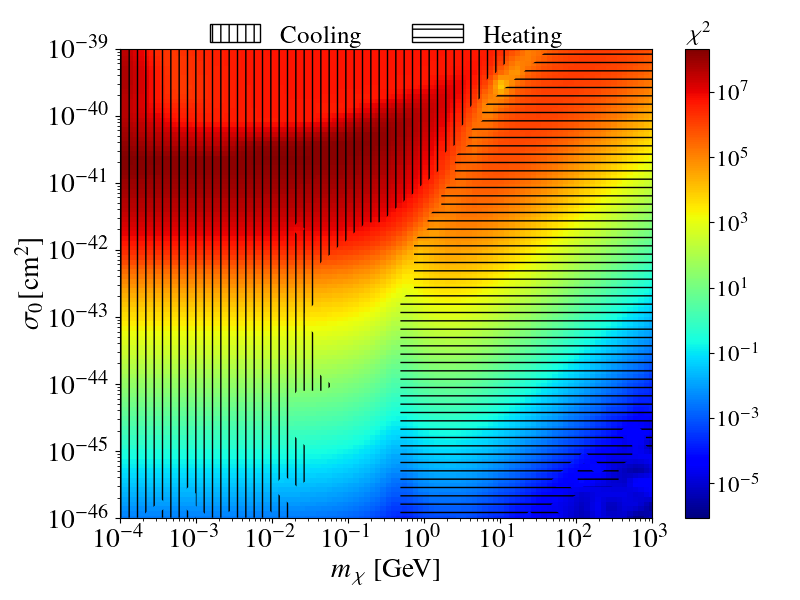

In [6]:
LineWidth = 2
FontSize = 20
zmax = 46.33
zmin = 10.83

summary_file = '/Users/cangtao/FileVault/GitHub/ResearchArchive/Hongmeng_SDM_2025_AA_SSPMA/data/cooling_rate.h5'
Tb0 = FST.Read_Fisher_DataSet(fst=-1.25, fesc=-1.35, LX=40.5, ast=0.5, fst3=-2.5, fesc3=-1.35, LX3=40.5, ast3=0.0, aesc=-0.3, E0=0.5, ALW=2.0, mx=0.0, sx42=0.0, type='Tb')

HM_data = FST.Get_HM_Data(tobs_yr=5, block_sun=1)
def Get_chi2(Tb, zax):
    freq = np.arange(30, 120, 0.061)
    redshifts = 1420/freq - 1
    t0 = np.interp(x = redshifts, xp = zax[::-1], fp = Tb0[::-1], left = np.nan, right = np.nan)
    t = np.interp(x = redshifts, xp = zax[::-1], fp = Tb[::-1], left = np.nan, right = np.nan)
    sigma = HM_data['sigma']
    chi2 = ((t - t0)/sigma)**2.0
    chi2 = np.sum(chi2)
    return chi2

with h5py.File(summary_file, 'r') as h5:
    z = h5['z'][:]
    sx = h5['sx'][:]
    mx = h5['mx'][:]
    Tax = h5['Tk'][:]
    Tbax = h5['Tb'][:]
    T0 = h5['Tk_fiducial'][:]

def apply_mask(dT):
    # Ensure data is in z range
    m1 = z < zmax
    z1 = z[m1]
    dT1 = dT[m1]
    m2 = z1 > zmin
    dT2 = dT1[m2]
    # Remove numerical fluctuations, set to -1 to skip masking
    m3 = np.abs(dT2) > -1
    dT3 = dT2[m3]
    return dT3

nm = len(mx)
ns = len(sx)

CoolHot = np.zeros([ns, nm])
Chi2_ax = np.zeros([ns, nm])
mask = z < zmax
for mid in np.arange(0, nm):
    for sid in np.arange(0, ns):
        T = Tax[mid, sid, :]
        dT = T - T0
        dT = apply_mask(dT)
        Hot = dT > 0
        Chi2_ax[sid, mid] = Get_chi2(Tbax[mid, sid, :], z)
        if (True in Hot) and (False in Hot):
            CoolHot[sid, mid] = 0
        elif True in Hot:
            CoolHot[sid, mid] = 1
        else:
            CoolHot[sid, mid] = -1
    
n = 100
mx_HiRes = np.linspace(mx[0], mx[-1], n)
sx_HiRes = np.linspace(sx[0], sx[-1], n)
Chi2_HiRes = np.zeros([n, n])
for mid in np.arange(0, n):
    
    mx_here = mx_HiRes[mid]
    mid_1 = PL.Find_Index(x = mx_here, x_axis = mx)
    mid_2 = mid_1 + 1
    m1 = mx[mid_1]
    m2 = mx[mid_2]
    c1 = Chi2_ax[:, mid_1]
    c2 = Chi2_ax[:, mid_2]
    c1, c2 = np.log10(c1), np.log10(c2)
    cax = (c2 - c1)*(mx_here - m1)/(m2 - m1) + c1
    chi2_here = np.interp(x = sx_HiRes, xp = sx, fp = cax, left = np.nan, right = np.nan)
    chi2_here = 10.0**chi2_here
    Chi2_HiRes[:, mid] = chi2_here

mx_HiRes = 10.0**mx_HiRes
sx_HiRes = 10.0**sx_HiRes
x_HiRes, y_HiRes = np.meshgrid(mx_HiRes, sx_HiRes)

mx = 10.0**mx
sx = 10.0**sx
x, y = np.meshgrid(mx, sx)

# ---- Make plot ----
fig,ax = plt.subplots()
fig.set_size_inches(8, 6)
# -- chi2 --
c=ax.pcolor(x_HiRes, y_HiRes, Chi2_HiRes, cmap='jet', rasterized = True, norm = LogNorm(vmin = Chi2_ax.min(), vmax=Chi2_ax.max()))

plt.xlabel('$m_\chi$ [GeV]',fontsize=FontSize,fontname='Times New Roman')
plt.ylabel('$\sigma_0[\mathrm{cm^2}]$',fontsize=FontSize,fontname='Times New Roman')
plt.xscale('log')
plt.yscale('log')
plt.xticks(size=FontSize)
plt.yticks(size=FontSize)
plt.xlim([mx.min(), mx.max()])
plt.ylim([sx.min(), sx.max()])
clb = plt.colorbar(c)
clb.ax.tick_params(labelsize=FontSize/1.2)
clb.ax.set_title('$\chi^2$', fontsize=FontSize/1.2)

# -- Cooling regions --
mask_hot = CoolHot < 0
ax.contourf(
    x, y, mask_hot,
    levels=[0.5, 1.5],      # select True region only
    hatches=['||'],       # choose hatch style: ////, \\\\, xxx, ...
    colors='none',          # keep underlying color
    alpha=0 ,                # transparent, hatching only
)
hatch_proxy = mpatches.Patch(
    facecolor='none',
    hatch='||',
    edgecolor='k',   # legend box border
)
handles, labels = ax.get_legend_handles_labels()
handles.append(hatch_proxy)
labels.append('Cooling')

# -- Heating regions --
mask_hot = CoolHot > 0
ax.contourf(
    x, y, mask_hot,
    levels=[0.5, 1.5],      # select True region only
    hatches=['--'],       # choose hatch style: ////, \\\\, xxx, ...
    colors='none',          # keep underlying color
    alpha=0 ,                # transparent, hatching only
)
hatch_proxy = mpatches.Patch(
    facecolor='none',
    hatch='--',
    edgecolor='k',   # legend box border
)

handles.append(hatch_proxy)
labels.append('Heating')

ax.legend(handles, labels,
          fontsize=FontSize/1.1,
          loc='upper center',
          bbox_to_anchor=(0.5, 1.1),
          ncol=2,
          frameon=False)

plt.tight_layout()
plt.savefig(plot_path+"/HeatMap.pdf", bbox_inches = 'tight')

# Correlations

In [7]:
mx = -4
NFG = 7

dx_ax = [0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.01] # NFG=0
for idx in np.arange(0, NFG):
    dx_ax.append(0.01)
dx_ax = np.array(dx_ax)

d = FST.Compute_Fisher_Matrix(
    params_to_exclude = ['ALW', 'E0', 'aesc'],
    mx = mx,
    get_samples = 0,
    Tobs = 5,
    dx_ax = dx_ax,
    n_samples = n_samples,
    NFG = NFG)

M = d['CovMat']
sx_idx = d['sx_idx']
dim = np.shape(M)[0]
for idx in np.arange(0, dim):
    sigma = d['params_sigma'][idx]
    K = M[sx_idx, idx]/(d['params_sigma'][idx] * d['params_sigma'][sx_idx])
    print(d['names'][idx] + "   {:.3f}".format(K))


fst   0.118
fesc   -0.538
LX   -0.572
ast   -0.268
fst3   0.534
fesc3   0.188
LX3   -0.293
ast3   -0.430
sx42   1.000
FG0   0.654
FG1   0.687
FG2   0.729
FG3   0.118
FG4   -0.493
FG5   -0.564
FG6   -0.576


In [8]:
PL.show_time()

Time now: 2026-11-22 12:47
